# Проект 1: анализ продаж интернет-магазина

#Загрузка данных

In [1]:
!wget https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx

--2026-11-16 17:53:54--  https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘Online Retail.xlsx.1’

Online Retail.xlsx.     [    <=>             ]  22.62M  30.6MB/s    in 0.7s    

2026-11-16 17:53:54 (30.6 MB/s) - ‘Online Retail.xlsx.1’ saved [23715344]



In [2]:
import pandas as pd

df = pd.read_excel('Online Retail.xlsx')

#Первый взгляд на данные

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.shape

(541909, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [7]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [8]:
df[df['Quantity'] <= 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


#Чистка данных

In [9]:
print('До чистки:', df.shape)

df = df.dropna(subset=['CustomerID'])
df = df[df['Quantity'] > 0]
df = df[df['UnitPrice'] > 0].copy()
df = df.drop_duplicates()

print('После чистки:', df.shape)

До чистки: (541909, 8)
После чистки: (392692, 8)


In [10]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [11]:
df['TotalPrice'].sum()

np.float64(8887208.894000001)

#Анализ на Python

In [12]:
df['Month'] = df['InvoiceDate'].dt.to_period('M')
revenue_by_month = df.groupby('Month')['TotalPrice'].sum()
revenue_by_month

,TotalPrice
Month,
2010-12,570422.730
2011-01,568101.310
2011-02,446084.920
2011-03,594081.760
2011-04,468374.331
2011-05,677355.150
2011-06,660046.050
2011-07,598962.901
2011-08,644051.040


In [13]:
top_products = df.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10)
top_products

,TotalPrice
Description,
"PAPER CRAFT , LITTLE BIRDIE",168469.60
REGENCY CAKESTAND 3 TIER,142264.75
WHITE HANGING HEART T-LIGHT HOLDER,100392.10
JUMBO BAG RED RETROSPOT,85040.54
MEDIUM CERAMIC TOP STORAGE JAR,81416.73
POSTAGE,77803.96
PARTY BUNTING,68785.23
ASSORTED COLOUR BIRD ORNAMENT,56413.03
Manual,53419.93


In [14]:
top_countries = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False).head(10)
top_countries

,TotalPrice
Country,
United Kingdom,7285024.644
Netherlands,285446.340
EIRE,265262.460
Germany,228678.400
France,208934.310
Australia,138453.810
Spain,61558.560
Switzerland,56443.950
Belgium,41196.340


#Анализ на SQL





In [15]:
!pip install duckdb -q

import duckdb

In [16]:
df['Month'] = df['Month'].astype(str)

###Топ-5 стран по выручке

In [17]:
duckdb.query('''
    SELECT Country,
           ROUND(SUM(TotalPrice), 2) AS revenue
    FROM df
    GROUP BY Country
    ORDER BY revenue DESC
    LIMIT 5
''').df()

,Country,revenue
0,United Kingdom,7285024.64
1,Netherlands,285446.34
2,EIRE,265262.46
3,Germany,228678.40
4,France,208934.31


###Выручка по месяцам (GROUP BY, агрегация по датам)

In [18]:
duckdb.query('''
    SELECT Month,
           ROUND(SUM(TotalPrice), 2) AS revenue
    FROM df
    GROUP BY Month
    ORDER BY Month
''').df()

,Month,revenue
0,2010-12,570422.73
1,2011-01,568101.31
2,2011-02,446084.92
3,2011-03,594081.76
4,2011-04,468374.33
5,2011-05,677355.15
6,2011-06,660046.05
7,2011-07,598962.90
8,2011-08,644051.04
9,2011-09,950690.20


###Топ-10 клиентов по выручке (COUNT DISTINCT)

In [19]:
duckdb.query('''
    SELECT CustomerID,
           ROUND(SUM(TotalPrice), 2) AS revenue,
           COUNT(DISTINCT InvoiceNo) AS orders
    FROM df
    GROUP BY CustomerID
    ORDER BY revenue DESC
    LIMIT 10
''').df()

,CustomerID,revenue,orders
0,14646.0,280206.02,73
1,18102.0,259657.30,60
2,17450.0,194390.79,46
3,16446.0,168472.50,2
4,14911.0,143711.17,201
5,12415.0,124914.53,21
6,14156.0,117210.08,55
7,17511.0,91062.38,31
8,16029.0,80850.84,63
9,12346.0,77183.60,1


###Клиенты с выручкой выше средней (подзапрос, HAVING)

In [20]:
duckdb.query('''
    SELECT CustomerID,
           ROUND(SUM(TotalPrice), 2) AS revenue
    FROM df
    GROUP BY CustomerID
    HAVING SUM(TotalPrice) > (
        SELECT AVG(customer_total)
        FROM (
            SELECT SUM(TotalPrice) AS customer_total
            FROM df
            GROUP BY CustomerID
        )
    )
    ORDER BY revenue DESC
''').df()

,CustomerID,revenue
0,14646.0,280206.02
1,18102.0,259657.30
2,17450.0,194390.79
3,16446.0,168472.50
4,14911.0,143711.17
...,...,...
866,12518.0,2056.89
867,17667.0,2055.51
868,14188.0,2054.36
869,16150.0,2053.02


### Накопительная выручка по месяцам (CTE, оконная функция)

In [21]:
duckdb.query('''
    WITH monthly AS (
        SELECT Month,
               SUM(TotalPrice) AS monthly_revenue
        FROM df
        GROUP BY Month
    )
    SELECT Month,
           ROUND(monthly_revenue, 2) AS monthly_revenue,
           ROUND(SUM(monthly_revenue) OVER (ORDER BY Month), 2) AS running_total
    FROM monthly
    ORDER BY Month
''').df()


,Month,monthly_revenue,running_total
0,2010-12,570422.73,570422.73
1,2011-01,568101.31,1138524.04
2,2011-02,446084.92,1584608.96
3,2011-03,594081.76,2178690.72
4,2011-04,468374.33,2647065.05
5,2011-05,677355.15,3324420.20
6,2011-06,660046.05,3984466.25
7,2011-07,598962.90,4583429.15
8,2011-08,644051.04,5227480.19
9,2011-09,950690.20,6178170.39


#Графики


###График 1 — выручка по месяцам(линия)

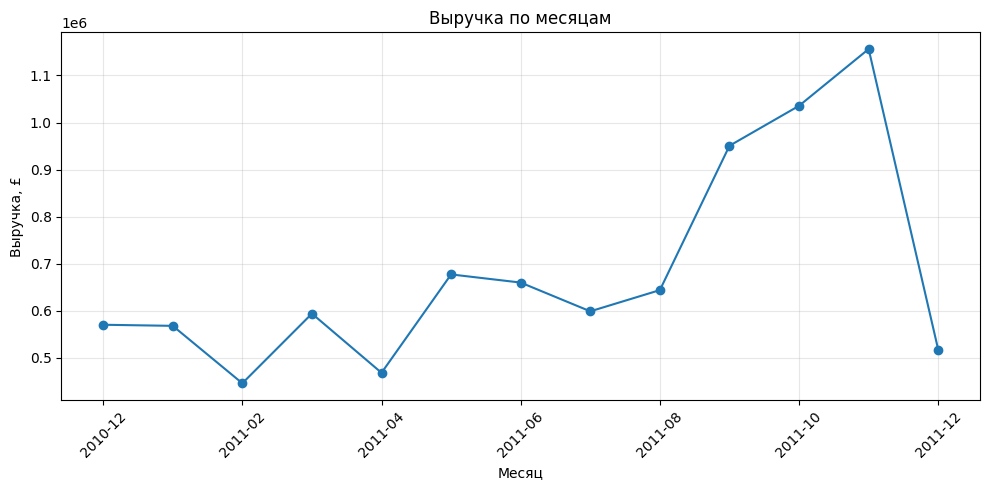

In [22]:
import matplotlib.pyplot as plt

revenue_by_month = df.groupby('Month')['TotalPrice'].sum()

plt.figure(figsize=(10, 5))
revenue_by_month.plot(kind='line', marker='o')
plt.title('Выручка по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Выручка, £')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

###График 2 — топ-10 товаров (горизонтальные столбцы)

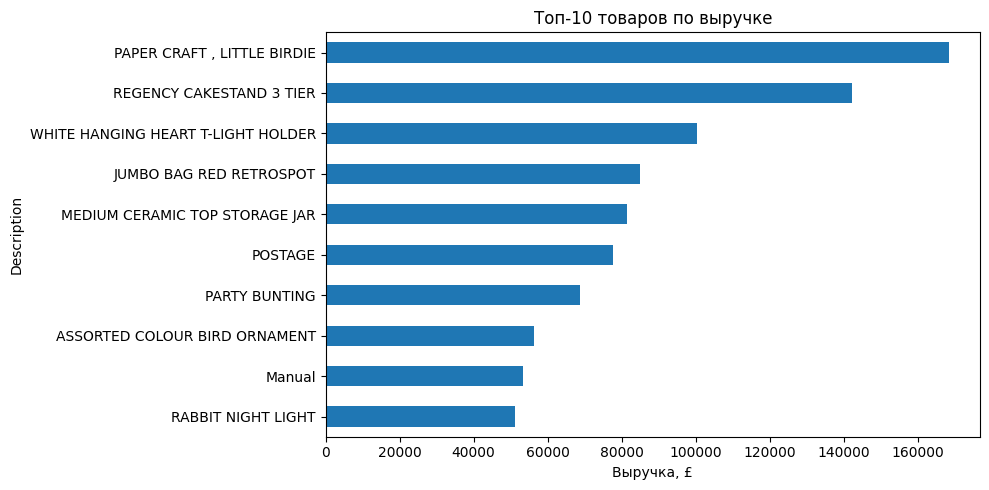

In [23]:
top_products = df.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top_products.sort_values().plot(kind='barh')
plt.title('Топ-10 товаров по выручке')
plt.xlabel('Выручка, £')
plt.tight_layout()
plt.show()

###График 3 — топ-10 стран без Великобритании

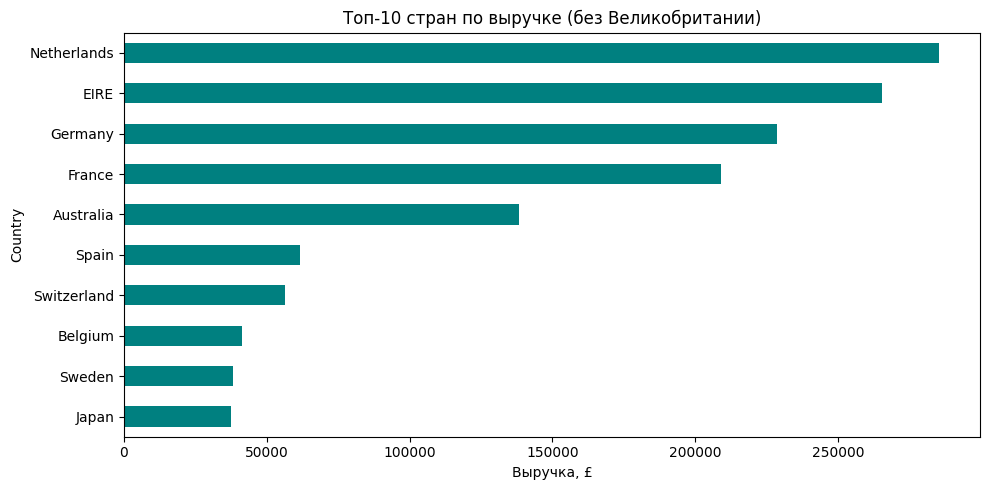

In [24]:
top_countries = (df[df['Country'] != 'United Kingdom']
                 .groupby('Country')['TotalPrice'].sum()
                 .sort_values(ascending=False).head(10))

plt.figure(figsize=(10, 5))
top_countries.sort_values().plot(kind='barh', color='teal')
plt.title('Топ-10 стран по выручке (без Великобритании)')
plt.xlabel('Выручка, £')
plt.tight_layout()
plt.show()

# Когортный анализ (удержание клиентов)

In [25]:
df['OrderMonth'] = df['InvoiceDate'].dt.to_period('M')
df['CohortMonth'] = df.groupby('CustomerID')['InvoiceDate'].transform('min').dt.to_period('M')

df[['CustomerID', 'InvoiceDate', 'OrderMonth', 'CohortMonth']].head()

,CustomerID,InvoiceDate,OrderMonth,CohortMonth
0,17850.0,2010-12-01 08:26:00,2010-12,2010-12
1,17850.0,2010-12-01 08:26:00,2010-12,2010-12
2,17850.0,2010-12-01 08:26:00,2010-12,2010-12
3,17850.0,2010-12-01 08:26:00,2010-12,2010-12
4,17850.0,2010-12-01 08:26:00,2010-12,2010-12


In [26]:
df['CohortIndex'] = (df['OrderMonth'] - df['CohortMonth']).apply(lambda x: x.n)

df[['CustomerID', 'OrderMonth', 'CohortMonth', 'CohortIndex']].head()

,CustomerID,OrderMonth,CohortMonth,CohortIndex
0,17850.0,2010-12,2010-12,0
1,17850.0,2010-12,2010-12,0
2,17850.0,2010-12,2010-12,0
3,17850.0,2010-12,2010-12,0
4,17850.0,2010-12,2010-12,0


In [27]:
cohort_data = df.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index()

cohort_pivot = cohort_data.pivot(index='CohortMonth',
                                 columns='CohortIndex',
                                 values='CustomerID')
cohort_pivot

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
cohort_size = cohort_pivot.iloc[:, 0]
retention = cohort_pivot.divide(cohort_size, axis=0).round(3) * 100
retention

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.6,32.3,38.4,36.3,39.8,36.3,34.9,35.4,39.5,37.4,50.3,26.6
2011-01,100.0,22.1,26.6,23.0,32.1,28.8,24.7,24.2,30.0,32.6,36.5,11.8,NaN
2011-02,100.0,18.7,18.7,28.4,27.1,24.7,25.3,27.9,24.7,30.5,6.8,NaN,NaN
2011-03,100.0,15.0,25.2,19.9,22.3,16.8,26.8,23.0,27.9,8.6,NaN,NaN,NaN
2011-04,100.0,21.3,20.3,21.0,19.7,22.7,21.7,26.0,7.3,NaN,NaN,NaN,NaN
2011-05,100.0,19.0,17.3,17.3,20.8,23.2,26.4,9.5,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.4,15.7,26.4,23.1,33.5,9.5,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.1,20.7,22.3,27.1,11.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.7,24.9,24.3,12.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


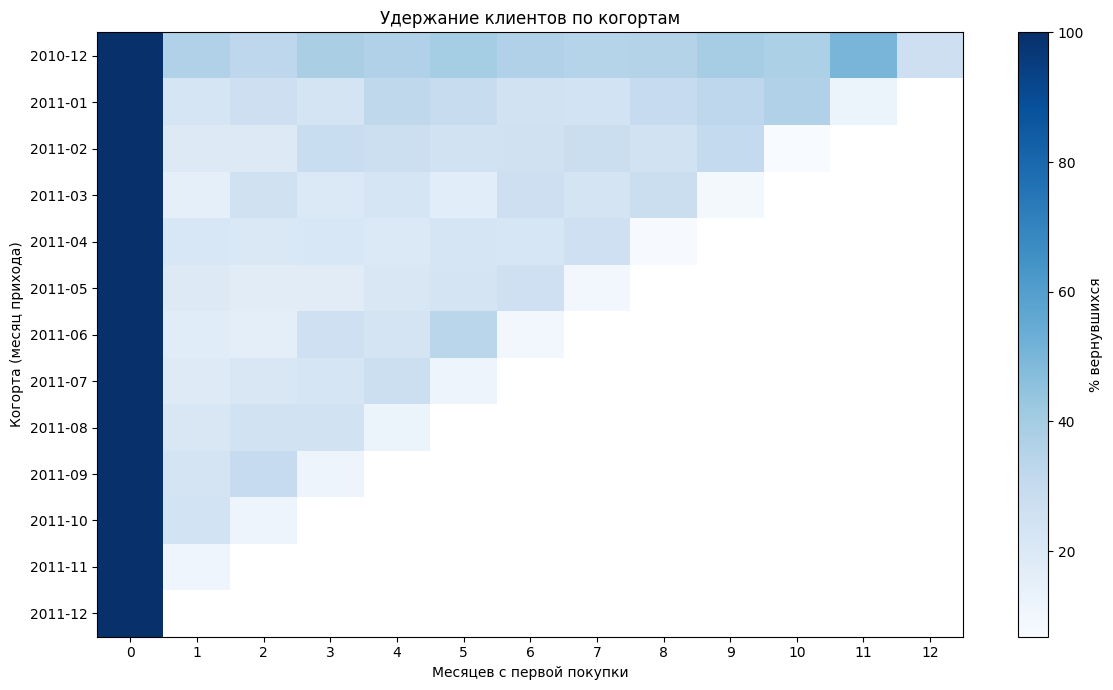

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
plt.imshow(retention, aspect='auto', cmap='Blues')
plt.colorbar(label='% вернувшихся')
plt.title('Удержание клиентов по когортам')
plt.xlabel('Месяцев с первой покупки')
plt.ylabel('Когорта (месяц прихода)')
plt.yticks(range(len(retention.index)), retention.index.astype(str))
plt.xticks(range(len(retention.columns)), retention.columns)
plt.tight_layout()
plt.show()

In [30]:
print('Выручка всего:', round(df['TotalPrice'].sum(), 2))
print('Период:', df['InvoiceDate'].min(), '—', df['InvoiceDate'].max())
print('Клиентов:', df['CustomerID'].nunique())

Выручка всего: 8887208.89
Период: 2010-12-01 08:26:00 — 2011-12-09 12:50:00
Клиентов: 4338


In [31]:
uk = df[df['Country'] == 'United Kingdom']['TotalPrice'].sum()
print('Доля UK:', round(uk / df['TotalPrice'].sum() * 100, 1), '%')

Доля UK: 82.0 %


In [32]:
print('Среднее удержание на 1-й месяц:', round(retention[1].mean(), 1), '%')

Среднее удержание на 1-й месяц: 20.6 %


# Выводы и рекомендации

## Выводы

1. Масштаб. За период с декабря 2010 по 9 декабря 2011 магазин заработал
   ~£8.89 млн от 4338 клиентов. Средний клиент приносит около £2000 —
   бизнес держится на оптовых покупателях.

2. Сезонность. Выручка уверенно растёт со второй половины года
   и достигает пика в ноябре (~£1.15 млн). Падение в декабре мнимое:
   данные обрываются на 9-м числе, месяц неполный.

3. География. 82% выручки даёт Великобритания. Среди остальных стран
   лидируют Нидерланды, Ирландия, Германия и Франция — это ближайший
   потенциал для роста.

4. Ассортимент. Выручка распределена по многим товарам, лидеры —
   подарочные и декоративные позиции. В топ попали служебные строки
   (POSTAGE, Manual) — их стоит исключать при анализе ассортимента.

5. Удержание. В среднем лишь ~20.6% новых клиентов возвращаются
   на следующий месяц. Повторные покупки - слабое место.

## Рекомендации

1. Готовиться к сезону заранее: наращивать запасы топ-товаров и маркетинг
   к сентябрю, чтобы максимально использовать осенне-зимний пик.

2. Снижать зависимость от UK: усиливать маркетинг в Нидерландах, Ирландии,
   Германии и Франции — там уже есть спрос.

3. Поднимать удержание: email-рассылки и скидка на вторую покупку
   в первый месяц, чтобы вернуть больше 20% новых клиентов.